# Mini-project 2: Reliability of a Stay Cable in a Cable-Stayed Bridge

**Student Name:** Amilcar Diaz

**CCID:** adiazgar

## Summary

Identify a problem from your own research area, professional field, or an engineering application of interest that involves uncertainty. Your task is to 1) describe the probability models and relevant model paramters or statistics for the important uncertain quantities or basic random variables; 2) define a quantity of interest that is a function of the basic random variables andiit meaningful to you or engineers in the relevant field; 3) perform probabilistic analyses at your best of your avility. Depending on the problem, this may include calculating its statistical moments and/or PDF, evaludating the linear correlation between the quantity of interest and basic random variables, or estimating the probability of one or more events of interest; and 4) identify and read a research paper related to the problem you selected, followed by a brief summary of what you undertand and what remains unclear at this point after you took this course.

## 1. Problem description

Stay cables carry the deck loads of a cable-stayed bridge to the pylons, so their tension is one of the most important quantities to monitor. If the tension is too high, the cable may approach its capacity; if it changes over time, it may indicate damage, loss of anchorage or changes in the structure.

A common and inexpensive way to estimate the tension of a cable in service is the **vibration method**:

1. An accelerometer is attached to the cable and records its ambient vibration (in this example, records of 200 s sampled at 50 Hz).
2. The Fast Fourier Transform (FFT) of the record is computed, and the fundamental frequency $f_1$ is obtained by averaging the five highest peaks.
3. The tension is computed with the taut-string formula, which relates the tension to the frequency, the mass per unit length and the length of the cable.

## 2. Basic random variables

The cable is made of 37 strands of 15.7 mm, grade 1860 MPa (ASTM A416-16), with a minimum breaking strength of 279 kN per strand.

| Variable | Mean | CV | Std. deviation | Distribution | Justification |
|---|---|---|---|---|---|
| $R$, resistance | 37 × 279 kN = 10 323 kN | 0.015 | 154.8 kN | Normal | Ali, Katsuchi and Yamada (2018); Nowak (1999) |
| $m$, total mass per unit length | 54 kg/m | 0.02 | 1.08 kg/m | Normal | Manufacturing tolerances (assumed) |
| $L$, effective length | 150 m | 0.03 | 4.50 m | Normal | Uncertainty due to dampers and anchorages (assumed) |
| $f_1$, fundamental frequency ($n$ = 1) | 0.96 Hz | 0.01 | 0.0096 Hz | Normal | Hypothetical measurement; resolution, noise, temperature |
| $T_{LL}$, live load | 1.18 × 1000 kN = 1180 kN | 0.18 | 212.4 kN | Lognormal | Pushka et al. (2022); Kulicki et al. (2007) |

**Live load:** the nominal CL-800 live load produces a nominal tension in the analyzed cable equal to $T_{LL,n}$ = 1000 kN. This value depends on the geometry and properties of the bridge and on the position of the cable, and it is assumed for this example. The parameters of the lognormal distribution are:

$$\zeta_{LL} = \sqrt{\ln\left(1 + CV_{LL}^2\right)} = \sqrt{\ln\left(1 + 0.18^2\right)} = 0.1786 \tag{1}$$

$$\lambda_{LL} = \ln\left(\mu_{LL}\right) - \frac{\zeta_{LL}^2}{2} = \ln(1180) - \frac{0.1786^2}{2} = 7.0573 \tag{2}$$

**Independence:** the variables are assumed to be statistically independent because they come from different sources, so the FOSM variance does not include covariance terms.

## 3. Quantities of interest

**Permanent tension** (taut-string formula, in N when $m$ is in kg/m, $L$ in m and $f_n$ in Hz):

$$T_{med} = 4\,m\,L^2\left(\frac{f_n}{n}\right)^2 \tag{3}$$

**Limit state function** (failure if $g < 0$):

$$g = R - \left[\,4\,m\,L^2\left(\frac{f_n}{n}\right)^2 + T_{LL}\right] \tag{4}$$

## 4. Probabilistic analysis

### 4.1 FOSM: mean and standard deviation of $T_{med}$ and $g$

FOSM linearizes the function at the mean values. Since the variables are independent, the variance has no covariance terms:

$$\sigma_g^2 \approx \sum_i \left(\frac{\partial g}{\partial x_i}\right)^2 \sigma_{X_i}^2 \tag{5}$$

**Mean of the permanent tension** (Eq. 3 evaluated at the mean values, $n = 1$):

$$\mu_{T} \approx 4\,\mu_m\,\mu_L^2\,\mu_f^2 = 4\,(54)\,(150)^2\,(0.96)^2 = 4\,478\,976\ \text{N} = 4479.0\ \text{kN} \tag{6}$$

**Partial derivatives of $T_{med}$** evaluated at the mean values:

$$\frac{\partial T_{med}}{\partial m} = 4\,L^2 f^2 = 4\,(150)^2\,(0.96)^2 = 82\,944\ \text{N per kg/m} = 82.94\ \text{kN per kg/m} \tag{7}$$

$$\frac{\partial T_{med}}{\partial L} = 8\,m\,L\,f^2 = 8\,(54)\,(150)\,(0.96)^2 = 59\,720\ \text{N/m} = 59.72\ \text{kN/m} \tag{8}$$

$$\frac{\partial T_{med}}{\partial f} = 8\,m\,L^2 f = 8\,(54)\,(150)^2\,(0.96) = 9\,331\,200\ \text{N/Hz} = 9331.2\ \text{kN/Hz} \tag{9}$$

**Standard deviation of the permanent tension:**

$$\sigma_T^2 \approx (82.94 \times 1.08)^2 + (59.72 \times 4.50)^2 + (9331.2 \times 0.0096)^2 = 89.58^2 + 268.74^2 + 89.58^2 = 88\,269\ \text{kN}^2 \tag{10}$$

$$\sigma_T \approx 297.1\ \text{kN}, \qquad CV_T = \frac{297.1}{4479.0} = 0.066 \tag{11}$$

| Variable | Contribution to $\sigma_T^2$ |
|---|---|
| $m$ | 8 024 kN² (9.1 %) |
| $L$ | 72 220 kN² (81.8 %) |
| $f_1$ | 8 024 kN² (9.1 %) |

The effective length $L$ dominates the uncertainty of the tension, because it appears squared in Eq. (3) and has the largest coefficient of variation.

**Mean of the limit state function** (Eq. 4 evaluated at the mean values):

$$\mu_g \approx \mu_R - \mu_T - \mu_{LL} = 10\,323 - 4479.0 - 1180 = 4664.0\ \text{kN} \tag{12}$$

**Standard deviation of the limit state function:** the derivatives of $g$ are $\partial g / \partial R = 1$, $\partial g / \partial T_{LL} = -1$, and $\partial g / \partial x_i = -\partial T_{med} / \partial x_i$ for $m$, $L$ and $f$, so:

$$\sigma_g^2 \approx \sigma_R^2 + \sigma_T^2 + \sigma_{LL}^2 = 154.8^2 + 297.1^2 + 212.4^2 = 157\,360\ \text{kN}^2 \tag{13}$$

$$\sigma_g \approx 396.7\ \text{kN} \tag{14}$$

### 4.2 Reliability index and probability of failure

$$\beta = \frac{\mu_g}{\sigma_g} = \frac{4664.0}{396.7} = 11.76 \tag{15}$$

$$P_f = \Phi(-\beta) = \Phi(-11.76) = 3.2 \times 10^{-32} \tag{16}$$

The result is compared with the target reliability index $\beta_T = 3.5$ (AASHTO LRFD, 75-year service life). A higher value could be required for stay cables. Since $\beta = 11.76 \geq \beta_T = 3.5$, the cable satisfies the target reliability.

### 4.3 Monte Carlo simulation

FOSM linearizes a nonlinear function ($L$ and $f$ appear squared) and assumes that $g$ is normal (while $T_{LL}$ is lognormal); Monte Carlo simulation is used to verify it.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.stats import norm

# Parameters of the basic random variables (Section 2)
mu_R, sigma_R = 10323.0, 154.845      # kN
mu_m, sigma_m = 54.0, 1.08            # kg/m
mu_L, sigma_L = 150.0, 4.5            # m
mu_f, sigma_f = 0.96, 0.0096          # Hz
lambda_LL, zeta_LL = 7.0573, 0.1786   # lognormal parameters of T_LL, Eqs. (1) and (2)
n = 1

# FOSM results (Section 4.1)
mu_T_fosm, sigma_T_fosm = 4479.0, 297.1   # kN, Eqs. (6) and (11)
mu_g_fosm, sigma_g_fosm = 4664.0, 396.7   # kN, Eqs. (12) and (14)

# Monte Carlo samples
N = 1_000_000
rng = np.random.default_rng(42)

R_s = rng.normal(mu_R, sigma_R, N)
m_s = rng.normal(mu_m, sigma_m, N)
L_s = rng.normal(mu_L, sigma_L, N)
f_s = rng.normal(mu_f, sigma_f, N)
LL_s = rng.lognormal(lambda_LL, zeta_LL, N)

# Permanent tension (kN), Eq. (3), and limit state function (kN), Eq. (4)
T_s = 4 * m_s * L_s**2 * (f_s / n)**2 / 1000
g_s = R_s - T_s - LL_s

n_fail = np.sum(g_s < 0)
beta_mc = g_s.mean() / g_s.std()

print(f"T_med (Monte Carlo): mean = {T_s.mean():.1f} kN, std = {T_s.std():.1f} kN")
print(f"T_med (FOSM):        mean = {mu_T_fosm:.1f} kN, std = {sigma_T_fosm:.1f} kN")
print()
print(f"g (Monte Carlo): mean = {g_s.mean():.1f} kN, std = {g_s.std():.1f} kN, beta = {beta_mc:.2f}")
print(f"g (FOSM):        mean = {mu_g_fosm:.1f} kN, std = {sigma_g_fosm:.1f} kN, beta = {mu_g_fosm / sigma_g_fosm:.2f}")
print()
if n_fail > 0:
    print(f"Pf Monte Carlo = {n_fail / N:.3e}  ({n_fail} failures)")
else:
    print(f"Pf Monte Carlo < {1 / N:.0e}  (0 failures in {N} samples)")

T_med (Monte Carlo): mean = 4483.9 kN, std = 297.3 kN
T_med (FOSM):        mean = 4479.0 kN, std = 297.1 kN

g (Monte Carlo): mean = 4658.9 kN, std = 397.0 kN, beta = 11.74
g (FOSM):        mean = 4664.0 kN, std = 396.7 kN, beta = 11.76

Pf Monte Carlo < 1e-06  (0 failures in 1000000 samples)


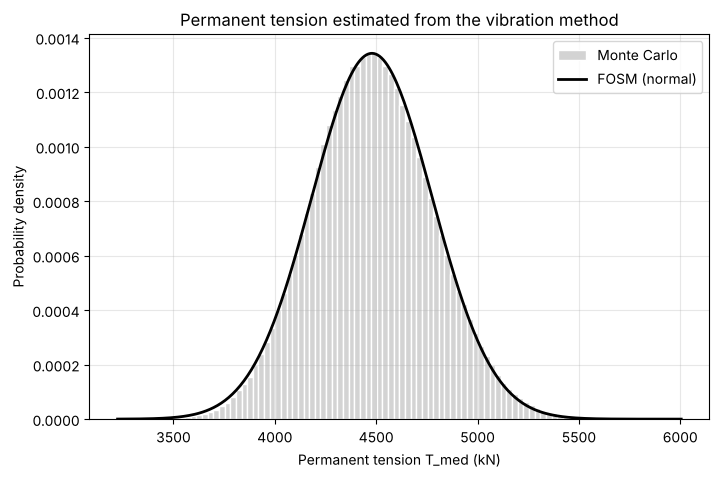

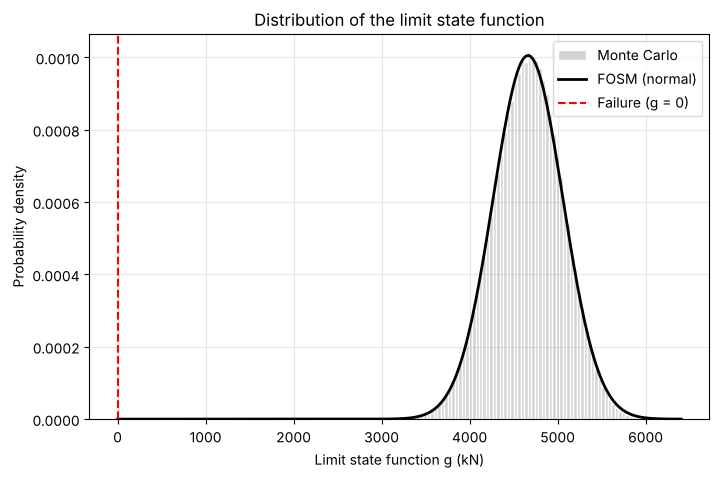

In [2]:
# Histogram of T_med with the FOSM normal approximation
T_line = np.linspace(T_s.min(), T_s.max(), 300)

plt.figure(figsize=(8, 5))
plt.hist(T_s, bins=100, density=True, color="lightgray", edgecolor="white", label="Monte Carlo")
plt.plot(T_line, norm.pdf(T_line, mu_T_fosm, sigma_T_fosm), color="black", linewidth=2, label="FOSM (normal)")
plt.xlabel("Permanent tension T_med (kN)")
plt.ylabel("Probability density")
plt.title("Permanent tension estimated from the vibration method")
plt.grid(alpha=0.3)
plt.legend()
plt.show()

# Histogram of g with the FOSM normal approximation
g_line = np.linspace(min(g_s.min(), 0), g_s.max(), 300)

plt.figure(figsize=(8, 5))
plt.hist(g_s, bins=100, density=True, color="lightgray", edgecolor="white", label="Monte Carlo")
plt.plot(g_line, norm.pdf(g_line, mu_g_fosm, sigma_g_fosm), color="black", linewidth=2, label="FOSM (normal)")
plt.axvline(0, color="red", linestyle="--", label="Failure (g = 0)")
plt.xlabel("Limit state function g (kN)")
plt.ylabel("Probability density")
plt.title("Distribution of the limit state function")
plt.grid(alpha=0.3)
plt.legend()
plt.show()

FOSM and Monte Carlo give practically the same mean, standard deviation and reliability index, so the nonlinearity of $g$ and the lognormal live load have a small effect for these coefficients of variation. However, Monte Carlo cannot verify the probability of failure: with $10^6$ samples no failures are observed, since the expected number of failures would be $10^6 \times 3.2 \times 10^{-32} \approx 0$.

### 4.4 Linear correlation between $g$ and the basic random variables

The correlation coefficients are computed from the Monte Carlo samples.

Correlation with g:
   R    = 0.391
   m    = -0.225
   L    = -0.677
   f1   = -0.226
   T_LL = -0.536


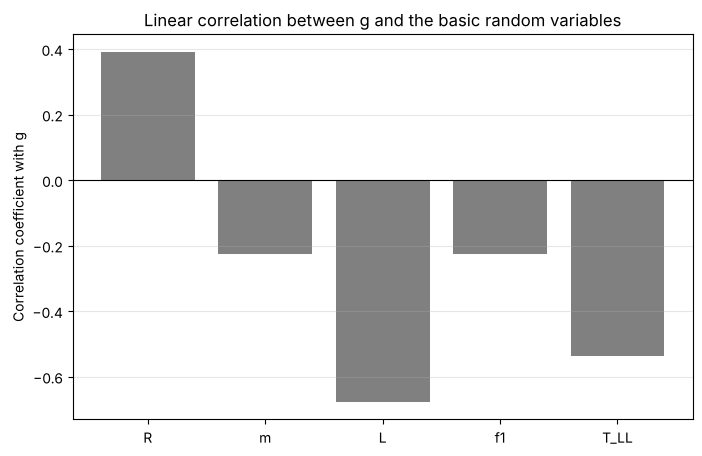

In [3]:
rho_R = np.corrcoef(g_s, R_s)[0, 1]
rho_m = np.corrcoef(g_s, m_s)[0, 1]
rho_L = np.corrcoef(g_s, L_s)[0, 1]
rho_f = np.corrcoef(g_s, f_s)[0, 1]
rho_LL = np.corrcoef(g_s, LL_s)[0, 1]

print("Correlation with g:")
print(f"   R    = {rho_R:.3f}")
print(f"   m    = {rho_m:.3f}")
print(f"   L    = {rho_L:.3f}")
print(f"   f1   = {rho_f:.3f}")
print(f"   T_LL = {rho_LL:.3f}")

plt.figure(figsize=(8, 5))
plt.bar(["R", "m", "L", "f1", "T_LL"], [rho_R, rho_m, rho_L, rho_f, rho_LL], color="gray")
plt.axhline(0, color="black", linewidth=0.8)
plt.ylabel("Correlation coefficient with g")
plt.title("Linear correlation between g and the basic random variables")
plt.grid(alpha=0.3, axis="y")
plt.show()

## 5. Research paper summary

**Hou, Sun and Chen (2020).** *Journal of Bridge Engineering*, 25(7). DOI: [10.1061/(ASCE)BE.1943-5592.0001573](https://doi.org/10.1061/(ASCE)BE.1943-5592.0001573)

- The paper uses the same vibration method to estimate cable tensions and the same reliability index used in this notebook.
- **Contribution of the paper:** cable tensions measured during one year of monitoring.
- **Contribution of this example:** propagation of the uncertainty in $m$, $L$ and $f$ to the estimated tension and to the reliability of the cable.

**What I understood:**

*(To be written by the author.)*

**What remains unclear:**

*(To be written by the author.)*

## 6. Assumptions and limitations

- The live load parameters come from another study (calibrated with the HL-93 load model) and are applied to the CL-800 load only for this example.
- The measured frequency and the coefficients of variation of $m$, $L$ and $f$ are illustrative.
- The taut-string formula neglects the bending stiffness of the cable, the sag (catenary effect) and the effect of the dampers.

## 7. References

- Ali, Katsuchi and Yamada (2018). *Journal of Structural Engineering, JSCE*, 64A: 99–108. DOI: 10.11532/structcivil.64A.99
- ASTM A416/A416M-16. *Standard Specification for Low-Relaxation, Seven-Wire Steel Strand for Prestressed Concrete.*
- Hou, Sun and Chen (2020). *Journal of Bridge Engineering*, 25(7). DOI: 10.1061/(ASCE)BE.1943-5592.0001573
- Kulicki et al. (2007). NCHRP 20-7.
- Nowak (1999). NCHRP Report 368.
- Pushka et al. (2022). *Canadian Journal of Civil Engineering*, 49(6): 899–909. DOI: 10.1139/cjce-2021-0031